# 04 · Feature Engineering

**Task:** at the end of month *t*, predict the **Tmax anomaly of month t+1** for every district (PLAN.md, D1).
**Input:** `data/processed/climate_monthly.parquet` → **Output:** `data/processed/features.parquet`

The feature logic and its justification are in `src/features.py`. This notebook builds the table, checks it for leakage and explains each feature group with evidence from the training data.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C, preprocessing as P, features as F, plotting as V
V.set_style(); pd.set_option("display.width", 160)
df = P.load_processed()
feat = F.build_features(df)
print("rows:", len(feat), "| dropped (insufficient history or no next month):", feat.attrs["dropped_rows"])
feat["split"].value_counts().reindex(["train", "validation", "test"]).to_frame("rows").assign(
    target_years=[f"{C.TRAIN_YEARS[0]}-{C.TRAIN_YEARS[1]}", f"{C.VAL_YEARS[0]}-{C.VAL_YEARS[1]}", f"{C.TEST_YEARS[0]}-{C.TEST_YEARS[1]}"])

rows: 38556 | dropped (insufficient history or no next month): 756


,rows,target_years
split,,
train,29484,2000-2019
validation,4536,2020-2022
test,4536,2023-2025


## 1. The feature set

| Group | Features | Why |
|---|---|---|
| Temperature memory | Tmax anomaly at t, t−1, t−2, 3-month mean; Tmin anomaly at t, t−1 | Anomalies persist (EDA F7: lag-1 r = 0.28) |
| Moisture memory | rainfall anomaly at t, 3- and 6-month mean; soil-moisture anomaly at t, t−1 | Wet soils cool the following month through evaporation (EDA F5) |
| Radiation | solar-radiation anomaly at t | Clear-sky, sunny months tend to precede heat |
| Large-scale context | national mean Tmax anomaly at t | Heat waves are regional; one district's value is noisy |
| Seasonal persistence | Tmax and national anomaly at t × sin/cos(target month) | Persistence is stronger before the monsoon than during it (EDA F7). These products let *linear* models use a season-dependent persistence. |
| Seasonality | target month as sin/cos; target-month Tmax climatology | Predictability differs by season (EDA F7) |
| Geography | elevation, latitude, longitude | Lets trees learn region-specific behaviour |

**Why sin/cos for the month?** Encoded as 1–12, December (12) and January (1) look far apart. On a circle, (sin, cos) puts them next to each other.

In [2]:
pd.DataFrame([(g, f) for g, fs in F.FEATURE_GROUPS.items() for f in fs], columns=["group", "feature"]).assign(
    **feat[F.FEATURES].describe().T[["mean", "std", "min", "max"]].round(3).reset_index(drop=True))

,group,feature,mean,std,min,max
0,Temperature memory,tmax_anom_l0,0.023,1.564,-7.674,7.317
1,Temperature memory,tmax_anom_l1,0.030,1.571,-7.674,7.317
2,Temperature memory,tmax_anom_l2,0.040,1.577,-7.674,7.317
3,Temperature memory,tmax_anom_3m,0.031,1.103,-4.866,5.218
4,Temperature memory,tmin_anom_l0,0.070,1.159,-4.969,5.579
5,Temperature memory,tmin_anom_l1,0.083,1.163,-4.969,5.579
6,Moisture memory,rain_anom_l0,1.050,34.524,-193.971,364.229
7,Moisture memory,rain_anom_3m,1.011,21.151,-107.071,231.393
8,Moisture memory,rain_anom_6m,0.855,15.041,-64.764,114.780
9,Moisture memory,soil_anom_l0,0.000,0.040,-0.221,0.260


## 2. Leakage checks

1. Every input row's `input_date` is exactly one month before its `target_date`.
2. `tmax_anom_l0` must equal the *previous* row's target for the same district. That proves lag 0 is month t and not the target month.
3. The climatology used for anomalies and for `target_tmax_clim` comes from 2000–2019 only (`src/preprocessing.py`).
4. The split uses the **target** year. The scaler and every hyperparameter are fitted inside the training folds (`src/models.py`).

In [3]:
gap = (feat["target_date"].dt.to_period("M") - feat["input_date"].dt.to_period("M")).apply(lambda x: x.n)
print("1. months between input and target:", gap.unique())
chk = feat.sort_values(["district_id", "target_date"])
prev_target = chk.groupby("district_id")[F.TARGET].shift(1)
ok = np.isclose(chk["tmax_anom_l0"], prev_target) | prev_target.isna()
print("2. lag-0 equals previous month's target in", f"{ok.mean():.1%}", "of rows")
print("3. first/last target date per split:")
feat.groupby("split")["target_date"].agg(["min", "max"]).loc[["train", "validation", "test"]]

1. months between input and target: [1]
2. lag-0 equals previous month's target in 100.0% of rows
3. first/last target date per split:


,min,max
split,,
train,2000-07-01,2019-12-01
validation,2020-01-01,2022-12-01
test,2023-01-01,2025-12-01


## 3. Evidence for the features (training period only)

Spearman correlation of each feature with the target, by target season. **Only training rows are used.** Looking at test-period correlations to choose features would itself be a form of leakage.

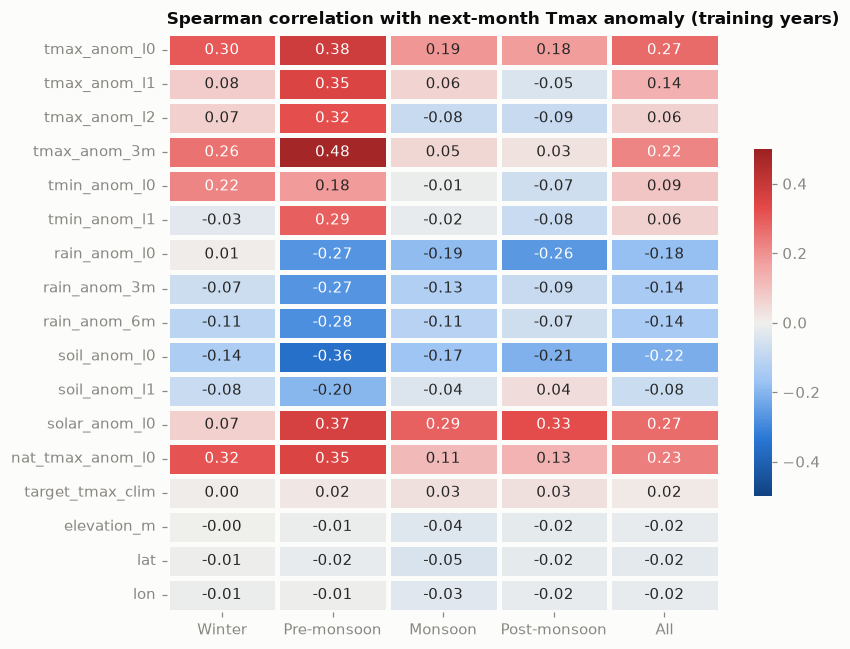

In [4]:
tr = feat[feat["split"] == "train"]
seasons = P.SEASON_ORDER
corr = pd.DataFrame({s: tr[tr["target_season"] == s][F.FEATURES].corrwith(tr[tr["target_season"] == s][F.TARGET], method="spearman")
                     for s in seasons})
corr["all"] = tr[F.FEATURES].corrwith(tr[F.TARGET], method="spearman")
corr = corr.drop(index=["month_sin", "month_cos", "l0_x_sin", "l0_x_cos", "nat_x_sin", "nat_x_cos"])
fig, ax = plt.subplots(figsize=(8, 6))
import seaborn as sns
sns.heatmap(corr, annot=True, fmt=".2f", cmap=V.DIVERGING, vmin=-.5, vmax=.5, linewidths=2, linecolor=V.SURFACE, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Spearman correlation with next-month Tmax anomaly (training years)"); ax.grid(False)
ax.set_xticklabels([s.split(" (")[0] if s != "all" else "All" for s in corr.columns], rotation=0)
fig.tight_layout(); V.save(fig, "fe_01_feature_target_correlation"); plt.show()

In [5]:
# Multicollinearity: highly correlated features matter for Ridge (shared coefficients) and for interpreting importance
cm = tr[F.FEATURES].corr().abs()
pairs = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack().sort_values(ascending=False)
pairs[pairs > 0.7].round(2).to_frame("|r|")

,,|r|
l0_x_sin,nat_x_sin,0.83
tmax_anom_l0,nat_tmax_anom_l0,0.81
target_tmax_clim,elevation_m,0.81
l0_x_cos,nat_x_cos,0.79
tmax_anom_l1,tmax_anom_3m,0.75
lat,lon,0.73
rain_anom_3m,rain_anom_6m,0.72
tmax_anom_l1,tmin_anom_l1,0.72
tmax_anom_l0,tmin_anom_l0,0.71


**Reading these results:**
* The strongest single predictors are this month's Tmax anomaly, its 3-month mean and the national anomaly. Their correlation with the target is positive but modest, consistent with EDA F7.
* Moisture features are negative: a wet month tends to be followed by a cooler month.
* Several temperature-memory features are strongly inter-correlated, as expected for overlapping windows. Ridge handles this through its L2 penalty, and tree models are unaffected. The overlap is a reason to read individual feature importances with care and look at *groups* (see notebook 06).

## 4. Save

In [6]:
feat.to_parquet(C.DATA_PROCESSED / "features.parquet", index=False)
print(feat.shape, "->", C.DATA_PROCESSED / "features.parquet")

(38556, 34) -> D:\University\Sem 7\DataScience\project\data\processed\features.parquet
